# Projet 4 — Prédire l'allocation Markowitz : k-NN et réseau de neurones

Pour chaque date $t$, on dispose d'un vecteur d'état $X_t$ (160 caractéristiques de marché) et de l'allocation Markowitz optimale $Y_t$ (max-Sharpe calculé après coup sur les 63 jours de bourse suivants, construite par `build_dataset.py`). L'objectif est de prédire $Y_t$ à partir de $X_t$.

Ce notebook présente d'abord le k-NN, qui sert de point de comparaison : à la date $t$, on cherche les $k$ dates du train dont $X$ ressemble le plus à $X_t$, et on détient la moyenne de leurs allocations $Y$. Les stratégies sont comparées au 1/N (répartition égale sur les 15 actions).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial.distance import cdist

np.random.seed(0)                       # k-NN est déterministe ; graine fixée par principe
DATA = Path("data")
if not (DATA / "processed/N63_wmax1/X.csv").exists():
    import zipfile
    zip_candidates = [Path("data_markowitz.zip"), Path("upload/data_markowitz.zip")]
    zip_path = next((p for p in zip_candidates if p.exists()), None)
    if zip_path is None:
        raise FileNotFoundError(
            "Données introuvables : placez data_markowitz.zip à côté du notebook, "
            "ou décompressez-le pour obtenir le dossier data/."
        )
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(".")
OUT = Path("results"); OUT.mkdir(exist_ok=True)
VAL, TEST = ("2017-01-02", "2019-12-31"), ("2020-01-02", "2025-09-30")

rd = lambda p: pd.read_csv(p, index_col=0, parse_dates=True)
F = DATA / "processed/N63_wmax1"
X, Y, meta, rets = rd(F/"X.csv"), rd(F/"Y.csv"), rd(F/"meta.csv"), rd(F/"returns.csv")
meta["label_end"] = pd.to_datetime(meta["label_end"])
macro = rd(DATA / "raw/macro.csv")
# taux sans risque quotidien (Euribor 3M connu la veille), comme dans build_dataset.py
rf = (macro["EURIBOR3M"].reindex(macro.index.union(rets.index)).ffill().shift(1)
      .reindex(rets.index) / 100 / 252).fillna(0)
ASSETS = list(Y.columns)                # 15 actions + CASH
R = rets.assign(CASH=rf)[ASSETS]        # rendements quotidiens, cash inclus
split, dates = meta["split"], X.index
print(X.shape, Y.shape, split.value_counts().to_dict())

(5082, 160) (5082, 16) {'train': 2749, 'test': 1474, 'val': 703, 'none': 156}


## Étape 1 — Charger et comprendre le dataset

On commence par vérifier les fichiers chargés, les dimensions, les dates et la séparation train/validation/test. Une ligne correspond à une date : `X` contient les caractéristiques de marché et `Y` l’allocation Markowitz associée.

L’exemple ci-dessous n’affiche que cinq caractéristiques et cinq poids pour rester lisible. Le modèle utilisera ensuite les 160 caractéristiques pour prédire l’allocation complète (15 actions et CASH).

In [2]:
# Vérifications de structure et d'alignement des observations
print(f"X : {X.shape[0]:,} dates × {X.shape[1]} caractéristiques")
print(f"Y : {Y.shape[0]:,} dates × {Y.shape[1]} actifs (CASH inclus)")
print(f"Dates identiques et dans le même ordre : {X.index.equals(Y.index) and X.index.equals(meta.index)}")
assert X.index.equals(Y.index) and X.index.equals(meta.index)

split_info = meta.reset_index(names="date").groupby("split").agg(
    nombre_dates=("split", "size"),
    première_date=("date", "min"),
    dernière_date=("date", "max"),
).sort_index()
display(split_info)

# Une observation d'exemple prise dans le train
date_exemple = meta.index[meta["split"] == "train"][0]
features_exemple = [
    "mom_21__OR.PA", "mom_21__BNP.PA", "vol_21__OR.PA",
    "market__vol_21", "macro__vix",
]
actifs_exemple = ["MC.PA", "OR.PA", "BNP.PA", "AIR.PA", "CASH"]

print(f"\nExemple de date train : {date_exemple.date()}")
print("Cinq caractéristiques de X_t :")
display(X.loc[[date_exemple], features_exemple].T.rename(columns={date_exemple: "valeur"}))
print("Poids Markowitz correspondants dans Y_t (extrait de cinq actifs) :")
display((100 * Y.loc[[date_exemple], actifs_exemple]).T.rename(columns={date_exemple: "poids (%)"}))

X : 5,082 dates × 160 caractéristiques
Y : 5,082 dates × 16 actifs (CASH inclus)
Dates identiques et dans le même ordre : True


,nombre_dates,première_date,dernière_date
split,,,
none,156,2005-11-21,2019-12-31
test,1474,2020-01-02,2025-09-30
train,2749,2006-01-02,2016-10-03
val,703,2017-01-02,2019-10-02



Exemple de date train : 2006-01-02
Cinq caractéristiques de X_t :


date,valeur
mom_21__OR.PA,0.017671
mom_21__BNP.PA,0.007342
vol_21__OR.PA,0.144495
market__vol_21,0.078201
macro__vix,12.070000


Poids Markowitz correspondants dans Y_t (extrait de cinq actifs) :


date,poids (%)
MC.PA,1.471523e-07
OR.PA,1.578132e+01
BNP.PA,8.931595e-07
AIR.PA,2.183447e-06
CASH,0.000000e+00


## Étape 2 — Standardiser les caractéristiques

Les 160 caractéristiques n'ont pas la même unité (rendements, volatilités annualisées, niveau du VIX, taux en %). Sans mise à l'échelle, les distances du k-NN seraient dominées par les variables de grande amplitude. On ramène chaque colonne $j$ à une échelle comparable :

$$z_{t,j}=\frac{x_{t,j}-\mu_{j,\text{train}}}{\sigma_{j,\text{train}}}$$

- $\mu$ et $\sigma$ sont estimés **sur le train uniquement**, puis la même transformation est appliquée à toutes les dates (train, val, test et zone de purge `none`, dont les labels peuvent servir de voisins). Aucune statistique de val/test n'est utilisée.
- Les $Y$ ne sont pas standardisés : ce sont des poids d'allocation.

In [3]:
# Standardisation ajustée sur le train uniquement
masque_train = (split == "train").to_numpy()
mu = X[masque_train].mean()
sigma = X[masque_train].std(ddof=0)
assert (sigma > 0).all(), "colonne constante sur le train : division par zéro"
Z = (X - mu) / sigma                     # une seule matrice, toutes les dates

# Contrôles
assert Z.index.equals(X.index) and Z.columns.equals(X.columns)   # mêmes dates, mêmes 160 colonnes
assert np.isfinite(Z.to_numpy()).all()                          # ni NaN ni infini
moy_tr, std_tr = Z[masque_train].mean(), Z[masque_train].std(ddof=0)
print(f"Train : |moyenne| max = {moy_tr.abs().max():.1e}, écart-type entre {std_tr.min():.4f} et {std_tr.max():.4f}")

# Val et test ne sont pas centrés sur 0 : c'est attendu, le marché a changé depuis le train
derive = Z.groupby(split).mean().T[["train", "val", "test"]]
print("\nCaractéristiques dont la moyenne standardisée dérive le plus sur le test :")
display(derive.reindex(derive["test"].abs().sort_values(ascending=False).index).head(5).round(2))

Train : |moyenne| max = 1.2e-15, écart-type entre 1.0000 et 1.0000

Caractéristiques dont la moyenne standardisée dérive le plus sur le test :


split,train,val,test
corrmkt_63__ORA.PA,-0.0,-1.05,-2.85
corrmkt_63__BN.PA,-0.0,-0.90,-2.18
corrmkt_63__TTE.PA,0.0,-1.04,-2.12
corrmkt_63__SAN.PA,0.0,-0.98,-2.02
eig2__global,-0.0,1.44,2.00


## Étape 3 — k plus proches voisins

### 3.1 Distances avec les dates du train

Pour chaque date de val et de test, on calcule la distance entre son $X$ standardisé et celui de chacune des dates du train. Seules les dates du train peuvent servir de voisins.

Deux distances sont calculées, pour les comparer ensuite sur la val :
- **euclidienne** : $\; d(a,b)=\sqrt{\sum_j (a_j-b_j)^2}$
- **Manhattan** : $\; d(a,b)=\sum_j |a_j-b_j|$

In [4]:
dates_train = Z.index[split == "train"]                     # voisins possibles
dates_cible = Z.index[split.isin(["val", "test"])]          # dates pour lesquelles on cherche des voisins
Z_train, Z_cible = Z.loc[dates_train].to_numpy(), Z.loc[dates_cible].to_numpy()

# Une ligne = une date de val/test, une colonne = une date du train
distances = {
    "euclidienne": pd.DataFrame(cdist(Z_cible, Z_train, "euclidean"), index=dates_cible, columns=dates_train),
    "manhattan":   pd.DataFrame(cdist(Z_cible, Z_train, "cityblock"), index=dates_cible, columns=dates_train),
}

# Contrôles
for nom, D in distances.items():
    assert D.shape == (len(dates_cible), len(dates_train))
    assert np.isfinite(D.to_numpy()).all() and (D.to_numpy() >= 0).all()   # ni manquante ni négative
    print(f"{nom} : {D.shape[0]} dates val/test × {D.shape[1]} dates train")

# Exemple : les 5 dates du train les plus proches d'un jour du krach COVID
date_ex = pd.Timestamp("2020-03-16")
print(f"\nLes 5 dates du train les plus proches du {date_ex.date()} :")
display(pd.concat({nom: D.loc[date_ex].nsmallest(5).round(1).reset_index().set_axis(["date", "distance"], axis=1)
                   for nom, D in distances.items()}, axis=1))

euclidienne : 2177 dates val/test × 2749 dates train
manhattan : 2177 dates val/test × 2749 dates train

Les 5 dates du train les plus proches du 2020-03-16 :


euclidienne           manhattan         
         date distance       date distance
0  2008-10-10     17.5 2008-10-10    170.9
1  2008-10-09     20.1 2008-10-09    199.9
2  2008-10-08     20.3 2008-10-08    201.3
3  2008-10-27     21.9 2008-10-27    220.4
4  2011-08-10     22.1 2008-10-16    222.3

In [5]:
# Les deux distances choisissent-elles les mêmes voisins ? Part de voisins en commun, moyenne sur toutes les dates val/test
De, Dm = distances["euclidienne"].to_numpy(), distances["manhattan"].to_numpy()
for k in [5, 20, 50, 200]:
    v_e, v_m = np.argpartition(De, k, axis=1)[:, :k], np.argpartition(Dm, k, axis=1)[:, :k]
    commun = np.mean([len(np.intersect1d(a, b)) / k for a, b in zip(v_e, v_m)])
    print(f"k = {k:>3} : {commun:.0%} des voisins en commun")

k =   5 : 46% des voisins en commun


k =  20 : 57% des voisins en commun
k =  50 : 63% des voisins en commun


k = 200 : 75% des voisins en commun


**Conclusion sur les deux distances**

- Les valeurs ne sont pas comparables entre elles (environ 17 en euclidienne contre 170 en Manhattan pour le 16/03/2020) : seul compte l'**ordre** des voisins.
- Sur l'exemple du krach COVID, les deux distances trouvent les mêmes périodes (octobre 2008, août 2011).
- Sur l'ensemble des dates, elles ne retiennent pourtant pas exactement les mêmes voisins : environ la moitié en commun pour les 5 plus proches, environ trois quarts pour les 200 plus proches. Le choix de la distance compte donc surtout quand $k$ est petit.
- Différence de principe : l'euclidienne élève les écarts au carré, donc une seule caractéristique très éloignée (par exemple un pic de VIX) peut suffire à écarter une date ; Manhattan donne le même poids à chaque écart et est moins sensible à ces valeurs extrêmes.
- Le choix entre les deux se fera sur la val, avec le choix de $k$.

### 3.2 Allocation k-NN

Pour chaque date de val/test, l'allocation est la moyenne des $Y$ de ses $k$ plus proches dates du train :
$$\hat w_t=\frac{1}{k}\sum_{j\in \text{voisins}_k(t)} Y_j$$
Chaque $Y_j$ est positif et somme à 1, donc leur moyenne aussi.

In [6]:
Y_train = Y.loc[dates_train].to_numpy()

def allocation_knn(D, k):
    """D : tableau des distances (dates val/test × dates train). Renvoie une allocation par date val/test."""
    voisins = np.argpartition(D.to_numpy(), k, axis=1)[:, :k]      # positions des k plus proches dates du train
    return pd.DataFrame(Y_train[voisins].mean(axis=1), index=D.index, columns=ASSETS)

# Contrôle sur un exemple
W_ex = allocation_knn(distances["euclidienne"], 20)
assert (W_ex.to_numpy() >= 0).all() and np.allclose(W_ex.sum(axis=1), 1)
# Comparaison avec l'allocation Markowitz optimale de la même date (Y, calculée avec les 63 jours suivants)
def comparer(d, W=W_ex):
    d = pd.Timestamp(d)
    comparaison = pd.DataFrame({"k-NN (k = 20)": W.loc[d], "Markowitz optimal (Y)": Y.loc[d]})
    voisins = distances["euclidienne"].loc[d].nsmallest(20).index
    print(f"Allocations du {d.date()}, en % (voisins pris entre {voisins.min():%m/%Y} et {voisins.max():%m/%Y}) :")
    display((100 * comparaison).round(1).T)
    print(f"Part du portefeuille à déplacer pour passer de l'une à l'autre : {0.5 * comparaison.diff(axis=1).iloc[:, 1].abs().sum():.0%}")
    # ce que chaque allocation a rapporté sur les 63 jours suivants, sans rééquilibrage
    rdt_actifs = (1 + R.loc[d + pd.Timedelta(days=1):meta.loc[d, "label_end"]]).prod() - 1
    print(f"Rendement sur les 63 jours suivants : k-NN {comparaison.iloc[:, 0] @ rdt_actifs:.1%}, "
          f"Markowitz optimal {comparaison.iloc[:, 1] @ rdt_actifs:.1%}, 1/N {rdt_actifs.iloc[:15].mean():.1%}\n")

comparer("2020-03-16")   # krach COVID
comparer("2025-09-30")   # date la plus récente disponible

Allocations du 2020-03-16, en % (voisins pris entre 01/2008 et 09/2011) :


,MC.PA,OR.PA,BN.PA,TTE.PA,VIE.PA,SAN.PA,BNP.PA,CS.PA,AIR.PA,SU.PA,DG.PA,SGO.PA,AI.PA,ORA.PA,CAP.PA,CASH
k-NN (k = 20),0.0,0.0,1.2,38.8,0.0,6.0,0.0,0.0,32.6,0.3,5.7,4.0,3.7,0.4,7.1,0.0
Markowitz optimal (Y),0.0,15.6,3.2,0.0,0.0,39.7,0.0,0.0,0.0,0.0,0.0,13.5,6.1,0.0,21.9,0.0


Part du portefeuille à déplacer pour passer de l'une à l'autre : 78%
Rendement sur les 63 jours suivants : k-NN 32.2%, Markowitz optimal 37.9%, 1/N 33.0%

Allocations du 2025-09-30, en % (voisins pris entre 11/2007 et 01/2008) :


,MC.PA,OR.PA,BN.PA,TTE.PA,VIE.PA,SAN.PA,BNP.PA,CS.PA,AIR.PA,SU.PA,DG.PA,SGO.PA,AI.PA,ORA.PA,CAP.PA,CASH
k-NN (k = 20),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,90.0
Markowitz optimal (Y),27.4,0.0,14.0,27.2,0.0,4.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.6,19.5,0.0


Part du portefeuille à déplacer pour passer de l'une à l'autre : 100%
Rendement sur les 63 jours suivants : k-NN -0.5%, Markowitz optimal 13.8%, 1/N 4.2%



**A-t-on bien prédit l'allocation optimale ?**

*16/03/2020 (krach COVID)*
- **La composition, non.** Il faudrait déplacer 78 % du portefeuille pour passer de l'une à l'autre. Le k-NN mise surtout sur TotalEnergies (39 %) et Airbus (33 %), alors que l'allocation optimale privilégie Sanofi (40 %), Capgemini (22 %), L'Oréal (16 %) et Saint-Gobain (14 %). Airbus est justement l'action qui a le moins progressé ensuite (+1 % en trois mois).
- **Le résultat, à peu près.** Sur les 63 jours suivants, le k-NN rapporte +32 %, contre +38 % pour l'optimal et +33 % pour le 1/N : après le krach, presque toutes les actions ont rebondi, donc rester investi suffisait.

*30/09/2025 (date la plus récente)*
- **Ni la composition, ni le résultat.** Le k-NN place 90 % en cash et 10 % sur Air Liquide ; l'allocation optimale est 100 % en actions (LVMH 27 %, TotalEnergies 27 %, Capgemini 20 %, Danone 14 %…). Les deux n'ont rien en commun (100 % à déplacer). Sur les trois mois suivants : −0,5 % pour le k-NN, +13,8 % pour l'optimal, +4,2 % pour le 1/N.
- La raison : les 20 voisins sont tous pris entre novembre 2007 et janvier 2008, juste avant la crise financière, quand l'allocation optimale était le cash. Le marché de 2025 ne ressemble à aucune période du train, et le k-NN se rabat sur des dates qui n'ont rien à voir. C'est la dérive vue à l'étape 2.

Deux dates ne suffisent pas pour conclure : la comparaison avec l'allocation optimale sur toutes les dates du test est faite à l'étape 4.

### 3.3 Évaluer une allocation (le « juge »)

Cette sous-partie ne prédit rien : elle transforme une suite d'allocations en résultat concret (combien on aurait gagné, avec quel risque). Toutes les stratégies passent devant ce même juge : 1/N, k-NN, puis le NN.

**Règles de la simulation**
- **Rééquilibrer**, c'est revenir aux poids voulus. Exemple : on veut 50 % LVMH / 50 % Total ; après un mois, LVMH a monté et pèse 57 %. On vend un peu de LVMH et on rachète du Total pour revenir à 50/50. Avec le k-NN, on ne revient pas aux mêmes poids : on prend la **nouvelle** allocation proposée ce jour-là.
- On rééquilibre **tous les 21 jours de bourse** (environ une fois par mois), avec l'allocation calculée **la veille** : on n'utilise jamais une information qu'on n'aurait pas eue.
- Entre deux rééquilibrages, on ne touche à rien : les poids bougent avec les prix.
- Chaque rééquilibrage coûte **0,1 %** du montant échangé, $\sum_i |w_i^{\text{cible}}-w_i^{\text{détenu}}|$.

**Mesures**
- **Rendement annualisé** et **volatilité annualisée** ;
- **Sharpe** : rendement au-delà de l'Euribor divisé par la volatilité (rendement par unité de risque) ;
- **Perte max** : la pire baisse depuis un sommet ;
- **Échangé/an** : combien de fois on a renouvelé tout le portefeuille dans l'année.

In [7]:
def backtest(W, debut, fin, reb=21, frais=1e-3):
    """UNE simulation : W = allocations cibles (dates × actifs). Renvoie les rendements quotidiens nets de frais et le volume échangé."""
    cible = W.reindex(R.index).ffill().shift(1)                     # décision prise à la clôture de la veille
    jours = cible.loc[debut:fin].dropna().index
    Rv, cible, pos = R.to_numpy(), cible.to_numpy(), R.index.get_indexer(jours)
    w, rend, echange = cible[pos[0]].copy(), [], 0.0                 # on démarre investi, sans frais initiaux
    for n, p in enumerate(pos):
        cout = 0.0
        if n % reb == 0:                                             # rééquilibrage
            dw = np.abs(cible[p] - w).sum(); echange += dw; cout = frais * dw; w = cible[p].copy()
        g = w @ (1 + Rv[p]); rend.append(g - 1 - cout); w = w * (1 + Rv[p]) / g   # les poids dérivent avec les prix
    return pd.Series(rend, index=jours), echange

def mesures(rend, echange):
    exces, richesse, ans = rend - rf.reindex(rend.index), (1 + rend).cumprod(), len(rend) / 252
    return {"Rdt ann.": richesse.iloc[-1] ** (1 / ans) - 1, "Vol ann.": rend.std() * np.sqrt(252),
            "Sharpe": exces.mean() / exces.std() * np.sqrt(252), "Perte max": (richesse / richesse.cummax() - 1).min(),
            "Échangé/an": echange / ans}

# Référence simple : 1/N sur les 15 actions, sans cash
W_1N = pd.DataFrame([[1 / 15] * 15 + [0.0]], index=[R.index[0]], columns=ASSETS)

**Problème : le résultat dépend du jour de départ**

Les jours de rééquilibrage se comptent à partir du premier jour de la simulation. Si on démarre le 02/01/2020, on rééquilibre le 02/01, le 31/01, le 02/03… ; si on démarre le 03/01, on rééquilibre le 03/01, le 03/02, le 03/03… Les règles sont les mêmes, mais les jours d'achat sont décalés.

- Le **1/N** revient toujours à la même cible (1/15 par action) : le jour du rééquilibrage ne change presque rien.
- Le **k-NN** change d'allocation presque chaque jour (en moyenne environ 15 % du portefeuille d'un jour à l'autre) : selon le jour où l'on rééquilibre, on n'achète pas le même portefeuille, et le résultat change.

Le graphique ci-dessous montre, sur la val, les 21 simulations possibles (une par jour de départ, du 1er au 21e jour de bourse) pour le 1/N et pour le k-NN de la 3.2 (euclidienne, $k = 20$). Toutes sont comparées à partir du 21e jour, date où les 21 ont démarré.

1/N : Sharpe de 1.05 à 1.11 selon le jour de départ


k-NN (euclidienne, k = 20) : Sharpe de 1.17 à 1.64 selon le jour de départ


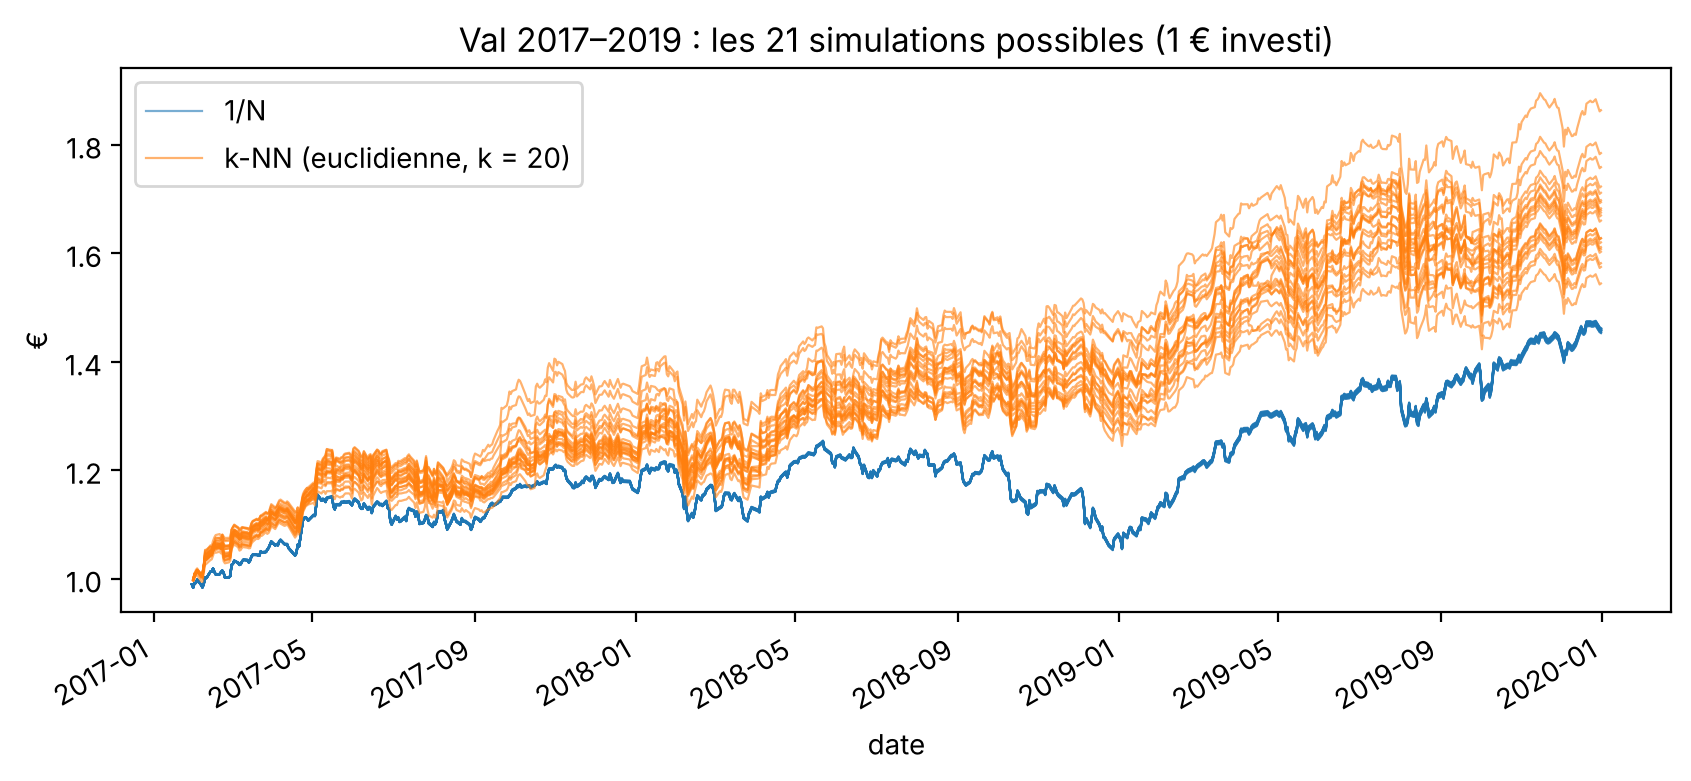

In [8]:
def simulations(W, debut, fin, reb=21):
    """Les 21 simulations possibles : la n-ième démarre le n-ième jour de bourse de la période."""
    jours = W.reindex(R.index).ffill().shift(1).loc[debut:fin].dropna().index
    return [backtest(W, jours[d], fin, reb) for d in range(reb)], jours[reb - 1]

fig, ax = plt.subplots(figsize=(10, 4))
for nom, W, couleur in [("1/N", W_1N, "tab:blue"), ("k-NN (euclidienne, k = 20)", W_ex, "tab:orange")]:
    sims, depart_commun = simulations(W, *VAL)
    for n, (rend, _) in enumerate(sims):
        (1 + rend.loc[depart_commun:]).cumprod().plot(ax=ax, color=couleur, lw=0.8, alpha=0.6, label=nom if n == 0 else None)
    s = [mesures(r, e)["Sharpe"] for r, e in sims]
    print(f"{nom} : Sharpe de {min(s):.2f} à {max(s):.2f} selon le jour de départ")
ax.set_title("Val 2017–2019 : les 21 simulations possibles (1 € investi)"); ax.set_ylabel("€"); ax.legend(); plt.show()

Sur la val, les 21 courbes du 1/N se superposent presque (Sharpe de 1,05 à 1,11), alors que celles du k-NN s'écartent nettement (Sharpe de 1,17 à 1,64). Une seule simulation ne suffit donc pas pour juger le k-NN.

**Solution : faire les 21 simulations et en prendre la moyenne**

On rééquilibre tous les 21 jours : la 22e simulation rééquilibrerait exactement aux mêmes dates que la 1re. Les 21 simulations couvrent donc tous les calendriers possibles. Le juge final :
1. lance les 21 simulations (règles inchangées : rééquilibrage tous les 21 jours, frais de 0,1 %) ;
2. calcule les mesures de chacune ;
3. renvoie leur **moyenne**, ainsi que le **pire** et le **meilleur** Sharpe, pour montrer à quel point le résultat dépend du hasard du calendrier.

C'est ce juge qui sert dans toute la suite.

In [9]:
def juge(W, debut, fin, reb=21):
    """Moyenne des mesures sur les 21 simulations, plus le pire et le meilleur Sharpe."""
    sims, _ = simulations(W, debut, fin, reb)
    m = pd.DataFrame([mesures(r, e) for r, e in sims])
    return {**m.mean().to_dict(), "Sharpe pire": m["Sharpe"].min(), "Sharpe meilleur": m["Sharpe"].max()}

print("1/N sur la val (moyenne des 21 simulations) :")
display(pd.DataFrame([juge(W_1N, *VAL)], index=["1/N"]).round(3))

1/N sur la val (moyenne des 21 simulations) :


,Rdt ann.,Vol ann.,Sharpe,Perte max,Échangé/an,Sharpe pire,Sharpe meilleur
1/N,0.132,0.125,1.078,-0.158,0.344,1.048,1.11


### 3.4 Choix de $k$ et de la distance sur la val (2017–2019)

On essaie 7 valeurs de $k$ avec les deux distances (14 combinaisons). Chacune passe devant le juge sur la val, et on garde celle qui a le **meilleur Sharpe moyen** sur les 21 simulations. Le test n'est pas utilisé pour ce choix.

Meilleur Sharpe moyen sur la val : distance euclidienne, k = 20


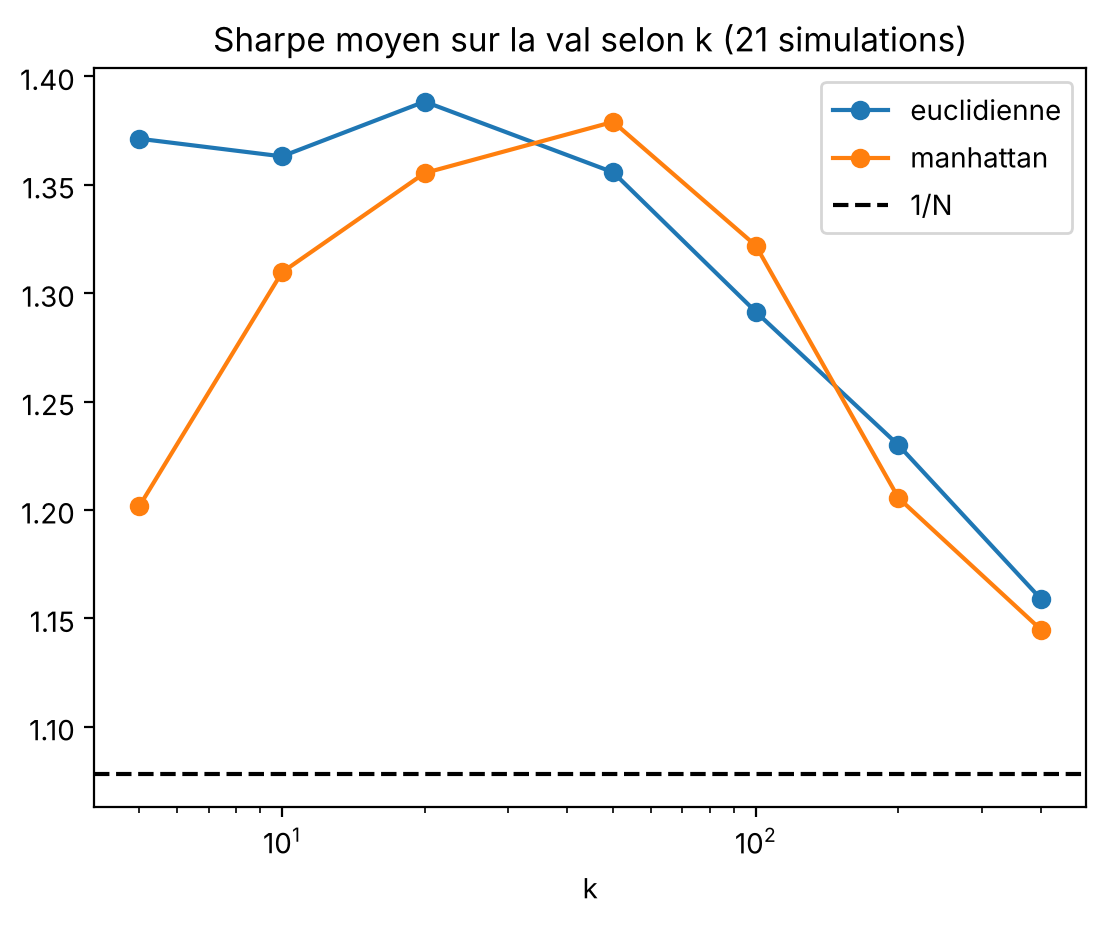

,distance,k,Rdt ann.,Vol ann.,Sharpe,Perte max,Échangé/an,Sharpe pire,Sharpe meilleur
2,euclidienne,20,0.176,0.125,1.388,-0.093,11.030,1.171,1.645
10,manhattan,50,0.164,0.118,1.379,-0.092,8.855,1.220,1.578
0,euclidienne,5,0.193,0.138,1.371,-0.111,13.398,1.091,1.660
1,euclidienne,10,0.182,0.132,1.363,-0.105,12.336,1.102,1.576
3,euclidienne,50,0.162,0.118,1.356,-0.091,8.963,1.166,1.582
9,manhattan,20,0.171,0.125,1.355,-0.095,11.267,1.138,1.629
11,manhattan,100,0.153,0.115,1.322,-0.093,6.868,1.209,1.428
8,manhattan,10,0.172,0.130,1.310,-0.101,12.689,1.077,1.601
4,euclidienne,100,0.150,0.116,1.291,-0.093,6.939,1.197,1.433
5,euclidienne,200,0.140,0.115,1.230,-0.094,4.994,1.159,1.325


In [10]:
liste_k = [5, 10, 20, 50, 100, 200, 400]
grille = pd.DataFrame([{"distance": nom, "k": k, **juge(allocation_knn(D, k), *VAL)}
                       for nom, D in distances.items() for k in liste_k])
meilleur = grille.loc[grille["Sharpe"].idxmax()]
dist_choisie, k_choisi = meilleur["distance"], int(meilleur["k"])
print(f"Meilleur Sharpe moyen sur la val : distance {dist_choisie}, k = {k_choisi}")

ax = grille.pivot(index="k", columns="distance", values="Sharpe").plot(marker="o", logx=True,
        title="Sharpe moyen sur la val selon k (21 simulations)")
ax.axhline(juge(W_1N, *VAL)["Sharpe"], color="k", ls="--", label="1/N"); ax.legend(); plt.show()
grille.sort_values("Sharpe", ascending=False).round(3)

**Conclusion de la 3.4**

*Pourquoi le ratio de Sharpe ?*
- Il mesure le rendement obtenu au-delà de l'Euribor **par unité de risque** (la volatilité). Deux stratégies au même rendement ne se valent pas si l'une est deux fois plus agitée ; le Sharpe fait la différence.
- C'est l'objectif même des allocations $Y$ : elles sont construites pour maximiser le Sharpe sur les 63 jours suivants. Juger le k-NN au Sharpe, c'est le juger sur ce qu'il cherche à reproduire.
- Il est calculé après frais, donc une version qui échange beaucoup son portefeuille est pénalisée.

*Pourquoi garder le $k$ et la distance qui le maximisent sur la val ?*
- Ce sont les deux seuls réglages du k-NN. On choisit celui qui aurait le mieux fonctionné sur une période que le modèle n'a pas vue (aucune date de val ne sert de voisin), sans toucher au test, qui reste réservé au verdict final (3.5).

*Ce que dit le tableau (moyenne des 21 simulations)*
- La meilleure combinaison est la distance **euclidienne avec $k = 20$** : Sharpe moyen de 1,39 (de 1,17 à 1,65 selon le jour de départ). Elle gagne de très peu : Manhattan avec $k = 50$ fait 1,38 et l'euclidienne avec $k = 5$ fait 1,37.
- En moyenne, **les 14 combinaisons battent le 1/N** (1,08) sur la val : l'avantage ne tient pas à un seul réglage chanceux.
- Plus $k$ est grand, plus l'allocation est stable (portefeuille échangé environ 13 fois par an pour $k=5$ contre 3 fois pour $k=400$) et moins le résultat dépend du jour de départ, mais plus elle se rapproche d'une allocation moyenne et le Sharpe baisse.
- Limite : la val ne couvre que 3 ans.

### 3.5 Test hors échantillon (2020–2025)

On applique sans rien réajuster :
- le **choix officiel**, retenu sur la val : distance euclidienne, $k = 20$ ;
- un **contrôle** : Manhattan avec $k = 50$, presque à égalité sur la val (Sharpe moyen 1,38 contre 1,39).

Le contrôle sert à vérifier que la conclusion ne dépend pas d'un réglage gagné de justesse. Il ne sert **pas** à choisir : si Manhattan fait mieux sur le test, on ne peut pas la retenir après coup, car ce serait utiliser le test pour régler le modèle.

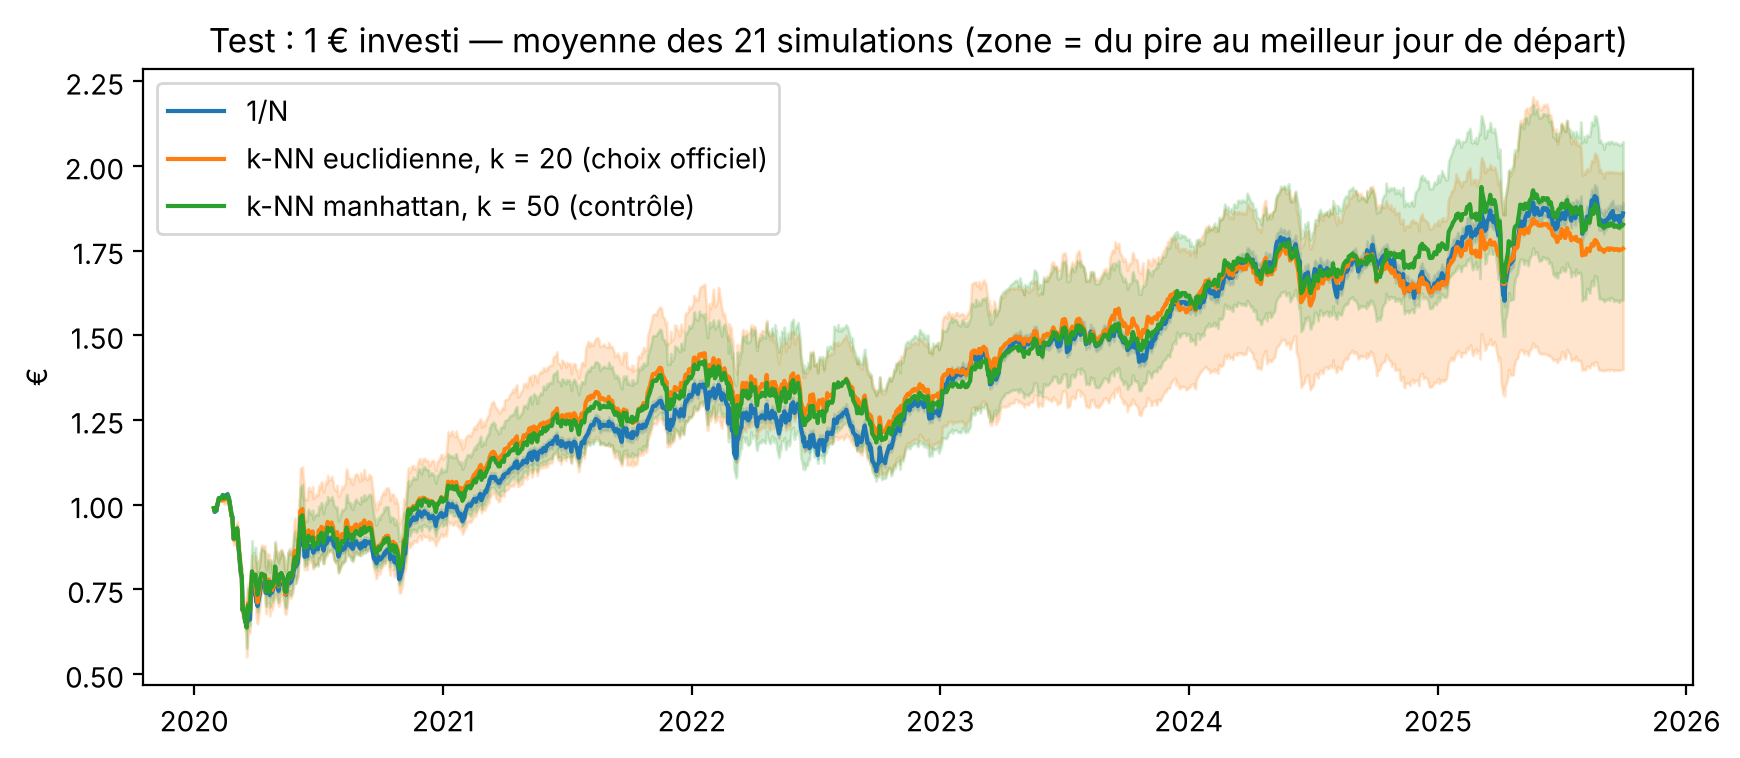

,Rdt ann.,Vol ann.,Sharpe,Perte max,Échangé/an,Sharpe pire,Sharpe meilleur
1/N,0.112,0.198,0.567,-0.381,0.506,0.558,0.582
"k-NN euclidienne, k = 20 (choix officiel)",0.104,0.202,0.525,-0.386,11.437,0.326,0.658
"k-NN manhattan, k = 50 (contrôle)",0.110,0.202,0.550,-0.383,9.450,0.444,0.664


In [11]:
W_knn_fixe = allocation_knn(distances[dist_choisie], k_choisi)         # choix officiel (meilleur Sharpe moyen sur la val)
W_knn_controle = allocation_knn(distances["manhattan"], 50)            # contrôle : deuxième sur la val
W_knn_fixe.to_csv(OUT / "knn_fixe_allocations.csv")                   # sauvegarde pour la comparaison finale

strategies = {"1/N": W_1N,
              f"k-NN {dist_choisie}, k = {k_choisi} (choix officiel)": W_knn_fixe,
              "k-NN manhattan, k = 50 (contrôle)": W_knn_controle}

fig, ax = plt.subplots(figsize=(10, 4))
for (nom, W), couleur in zip(strategies.items(), ["tab:blue", "tab:orange", "tab:green"]):
    sims, depart_commun = simulations(W, *TEST)
    courbes = pd.concat([(1 + r.loc[depart_commun:]).cumprod() for r, _ in sims], axis=1)
    ax.fill_between(courbes.index, courbes.min(axis=1), courbes.max(axis=1), color=couleur, alpha=0.2)
    ax.plot(courbes.index, courbes.mean(axis=1), color=couleur, label=nom)
ax.set_title("Test : 1 € investi — moyenne des 21 simulations (zone = du pire au meilleur jour de départ)")
ax.set_ylabel("€"); ax.legend(); plt.show()

pd.DataFrame({nom: juge(W, *TEST) for nom, W in strategies.items()}).T.round(3)

**Conclusion de la 3.5**

- En moyenne sur les 21 simulations, **aucun des deux k-NN ne bat le 1/N sur le test** : Sharpe de 0,52 (choix officiel) et 0,55 (contrôle), contre 0,57 pour le 1/N. Les rendements sont proches (10,4 % et 11,0 % par an contre 11,2 %), avec la même perte maximale (environ −38 %).
- **Le k-NN est beaucoup plus incertain que le 1/N.** Selon le jour de départ, son Sharpe va de 0,33 à 0,66 (choix officiel) ou de 0,44 à 0,66 (contrôle), contre 0,56 à 0,58 pour le 1/N. Avec un calendrier favorable il bat le 1/N, avec un calendrier défavorable il est loin derrière : rien ne permet de dire qu'il fait mieux.
- Sur le graphique, les k-NN sont en moyenne légèrement devant le 1/N de 2020 à 2023, puis l'euclidienne décroche en 2024–2025.
- Les deux réglages donnent la même conclusion : elle ne dépend pas d'un réglage gagné de justesse.
- Les k-NN échangent leur portefeuille 9 à 11 fois par an, contre 0,5 fois pour le 1/N.

### 3.6 Conclusion (voisins pris dans le train uniquement)

- **Sur la val (2017–2019)**, le k-NN fait nettement mieux que le 1/N : Sharpe moyen de 1,39 (euclidienne, $k=20$) contre 1,08, et c'est vrai pour les 14 réglages testés.
- **Sur le test (2020–2025)**, l'avantage disparaît : 0,52 contre 0,57 en moyenne, avec un résultat très dépendant du jour de départ (de 0,33 à 0,66).
- Explication probable : à l'étape 2, on a vu que le marché du test s'éloigne fortement de celui du train (corrélations au CAC beaucoup plus faibles). Les voisins pris uniquement entre 2006 et 2016 ressemblent de moins en moins aux dates à prédire ; le 30/09/2025, par exemple, ils viennent tous de fin 2007 (3.2).
- Piste d'amélioration, non traitée ici : un k-NN « walk-forward », où les dates récentes deviennent des voisins possibles au fil du temps (dès que leurs 63 jours suivants sont passés), pourrait mieux suivre ce changement de marché.

## Étape 4 — Comparer les prédictions sans rééquilibrage

Cette étape sert uniquement à comparer le k-NN et le NN sur la même base, sans aucune règle de rééquilibrage.

À chaque date $t$ du test, on prend l'allocation prédite $\hat w_t$ et on la garde **telle quelle pendant 63 jours de bourse**, l'horizon sur lequel les $Y$ sont construits, sans rééquilibrage ni frais. Deux mesures :
- **rendement moyen sur 63 jours** : $\hat w_t \cdot R_{t \to t+63}$, moyenne sur toutes les dates du test ;
- **écart avec $Y$** : part du portefeuille à déplacer pour passer de la prédiction à l'allocation optimale, $\tfrac12\sum_i|\hat w_{t,i}-Y_{t,i}|$ (0 % = identique, 100 % = rien en commun).

Le 1/N est ajouté comme simple point de repère. Le NN sera ajouté au tableau avec la même fonction.

In [12]:
R_fwd = rd(F / "R_fwd.csv")                        # rendement de chaque actif sur les 63 jours suivant chaque date

def sans_reequilibrage(W, debut=TEST[0], fin=TEST[1]):
    """Allocations prédites gardées 63 jours sans rééquilibrage : rendement moyen et écart moyen avec Y."""
    W = W.loc[debut:fin]
    return {"Rdt moyen sur 63 j": (W * R_fwd.loc[W.index]).sum(axis=1).mean(),
            "Écart avec Y": 0.5 * (W - Y.loc[W.index]).abs().sum(axis=1).mean()}

comparaison_sans_reeq = {
    "k-NN (euclidienne, k = 20)": sans_reequilibrage(W_knn_fixe),
    "1/N (repère)": sans_reequilibrage(pd.DataFrame(1 / 15, index=dates_cible, columns=ASSETS).assign(CASH=0.0)),
    # "NN": sans_reequilibrage(W_nn),   # à ajouter quand le NN sera prêt
}
pd.DataFrame(comparaison_sans_reeq).T.style.format("{:.1%}")

,Rdt moyen sur 63 j,Écart avec Y
"k-NN (euclidienne, k = 20)",3.4%,78.1%
1/N (repère),3.5%,71.4%


**Conclusion de l'étape 4**

Sur le test, le k-NN rapporte en moyenne 3,4 % sur 63 jours, contre 3,5 % pour le 1/N, et il faudrait déplacer 78 % de son portefeuille pour retrouver l'allocation optimale, contre 71 % pour le 1/N. Sans rééquilibrage, le k-NN ne fait donc pas mieux que le simple repère. Le NN sera jugé sur ces deux mêmes chiffres.